# Forest change from NISAR radar backscatter and coherence (Python)

**Question.** Where and when was forest cut near Pigeon Springs, Washington, during NISAR's first year of calibrated data, and how can radar tell a harvest from a seasonal change?

By the end of this lesson you will have maps and charts like these, made from a year of NISAR radar images: harvested stands colored by the date of cutting, the winter coherence that separates tall forest from young stands, and time series that show how each kind of forest behaved.

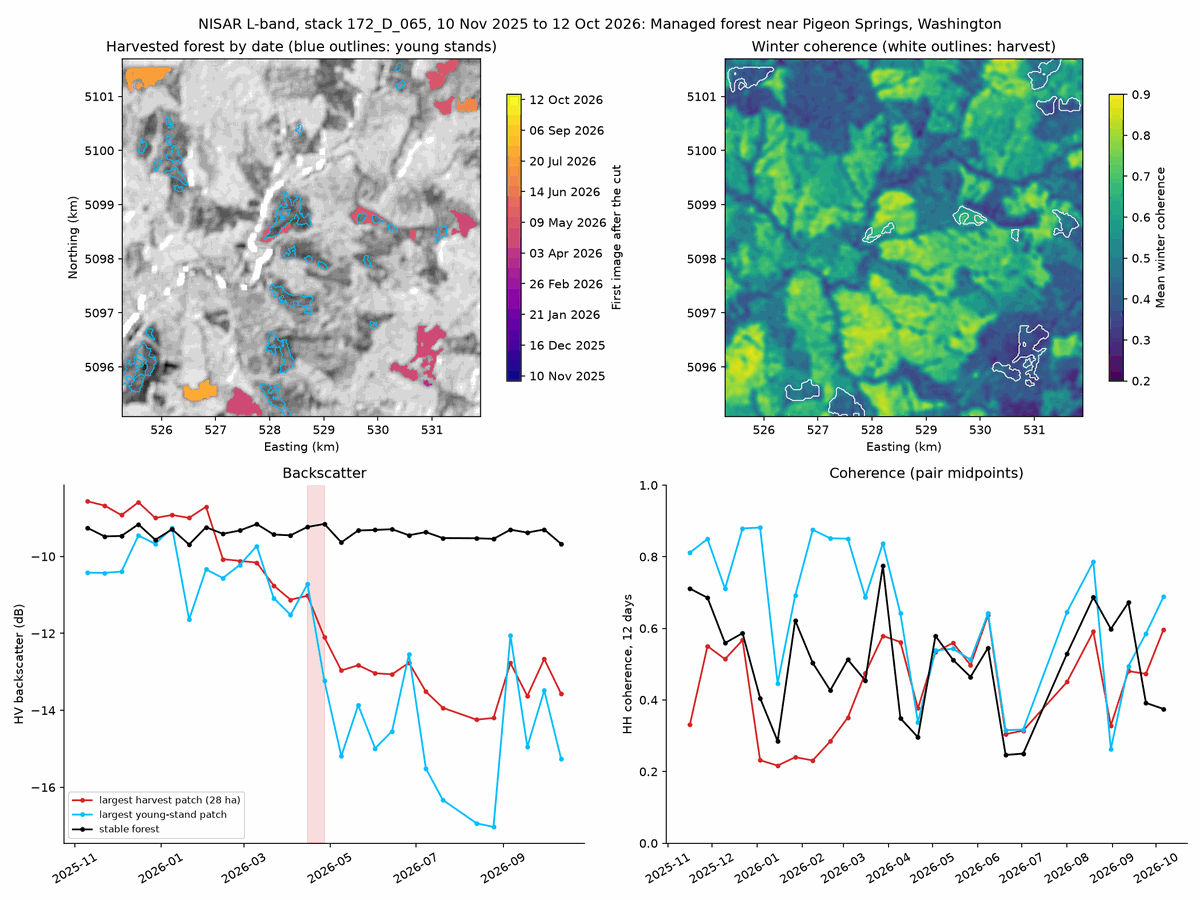

**You will learn to**

1. find NISAR radar products in NASA's catalog and read their names, maturity levels, and viewing geometry;
2. read a small window from a 7 GB HDF5 file over the internet, without downloading the file, and turn radar backscatter into maps;
3. build a year-long backscatter time series, flag places where forest backscatter dropped, and date each change;
4. use interferometric coherence to tell harvested forest from young stands whose backscatter falls in the dry season.

## Before starting

- **Setup.** Run the [getting-started notebook](../getting-started/) first. You need the Trees from Space Python environment (it already includes `h5py`) and an Earthdata Login stored in `~/.netrc` ([guide](../../docs/getting-started/earthdata-login.md)).
- **CHPC.** Run the getting-started notebook in the same kind of OnDemand session first. If it reports that the session can reach NASA, run this lesson as it is. If not, fetch the data with a short transfer job, after which the whole notebook runs offline from the cache ([CHPC guide](../../docs/getting-started/chpc.md)).
- **Data volume.** The lesson reads small windows from 55 NISAR files: about 0.7 GB moves over the network on the first run, and about 40 MB stays in the cache. The same files downloaded whole would be about 250 GB.
- **Time.** This is a long lesson, about 60 minutes of reading and running in three parts, plus about 10 minutes of data reading on the first run. Reruns take less than a minute.
- **Related lessons.** The [HLS](../hls-vegetation-map/) and [Sentinel-2](../sentinel2-stac/) lessons map vegetation with optical images, which clouds and darkness block; radar sees through both. The [GEDI lesson](../gedi-canopy-height/) measures canopy height directly. This lesson can be done on its own.
- **Tested environments.** See the [lesson README](README.md).

## The data in brief

**NISAR** (the NASA-ISRO Synthetic Aperture Radar mission, launched in July 2025) carries an imaging radar. A radar sends its own microwave pulses and records the echoes, so it works day and night and through clouds. NISAR images most of Earth's land every 12 days, from two directions: northbound (**ascending**) and southbound (**descending**) passes.

**L-band and forests.** NISAR's L-band radar uses a wavelength of about 24 cm. Waves this long pass through leaves and needles and scatter mostly from branches and trunks, so L-band responds to the woody structure of a forest. Clearing a forest removes those scatterers, and the radar signal drops.

**Polarization.** The radar sends and receives waves that vibrate either horizontally (H) or vertically (V). **HH** means sent H, received H. **HV** means sent H, received V. A forest canopy, with branches at every angle, turns much of the signal from H to V, so **HV is the channel most sensitive to forest**. Bare ground and short vegetation return little HV.

**Backscatter and decibels.** Backscatter is the fraction of the radar's power that comes back, per unit area. NISAR's **GCOV** product (geocoded polarimetric covariance) stores it as **gamma-nought** (γ⁰), a ratio with no units that has already been corrected for terrain (see below). Values span several orders of magnitude, so they are usually shown in **decibels**: dB = 10 log₁₀(γ⁰). A value of −10 dB means 0.1, and a change of −3 dB means the power halved.

**Terrain.** The radar looks to one side. Slopes that face the radar return more power, and slopes that face away return less or lie in shadow. GCOV applies a **radiometric terrain correction** that removes most of this effect, and it supplies a factor to convert γ⁰ to the older convention, **sigma-nought** (σ⁰).

**Speckle.** Each radar pixel adds the echoes of many scatterers, which interfere with each other. The result is a grainy pattern called **speckle**. Averaging neighboring pixels or several dates reduces it, at the cost of detail.

**Coherence.** NISAR's **GUNW** product (geocoded unwrapped interferogram) compares two images taken 12 days apart. Its **coherence** runs from 0 to 1 and measures how similar the echo stayed: near 1 when the scatterers did not move or change, lower when they did. Wind moves leaves and branches, and rain or freezing changes their water content, so tall forest loses coherence quickly, while bare ground and short vegetation keep it longer.

**Maturity.** NISAR products are released in stages. **Beta** products (released February 2026) were not yet calibrated. **Provisional** products (from July 2026) are calibrated but may still change. **Validated** products are expected later. This lesson uses provisional products and shows why the two releases should not be mixed.

**Limits to keep in mind.** Calibration is provisional. Backscatter also changes with moisture, freezing, and wind, not only with forest structure. In very dense, high-biomass forest, L-band backscatter saturates and stops increasing with biomass. On steep slopes, parts of the image fall in radar shadow or are compressed (layover).

## Settings

Everything you might change is in the next cell. Coordinates are longitude and latitude in decimal degrees (WGS84), in the order **west, south, east, north**. Dates use the format `"YYYY-MM-DD"`. If you run this notebook as a batch job, the job uses the values saved in this cell.

In [ ]:
# Study area: a box of longitude/latitude in degrees, ordered (west, south, east, north).
SITE_ID = "cowlitz"
SITE_NAME = "Managed forest near Pigeon Springs, Washington"
BBOX = (-122.673, 46.009, -122.588, 46.068)

# Search window: NISAR's first year of calibrated (provisional) data over the site.
START_DATE = "2025-11-01"
END_DATE = "2026-10-31"

# Products: radar backscatter (GCOV) and 12-day interferograms (GUNW), provisional release.
GCOV_SHORT_NAME = "NISAR_L2_GCOV_PROVISIONAL_V1"
GUNW_SHORT_NAME = "NISAR_L2_GUNW_PROVISIONAL_V1"

# Viewing geometry, written as in the file names: track_direction_frame.
# None picks the combination with the most dates over the box.
STACK = "172_D_065"

# Date of the single image in Part A ("YYYY-MM-DD"); None uses the latest date.
MAP_DATE = None

# Request limit: the most granules to search for, per product.
MAX_GRANULES = 200

# Change detection (Parts B and C).
BOXCAR_PIXELS = 5  # speckle filter: average over this many 20 m pixels on each side
FOREST_MIN_DB = -12.5  # HV above this (dB) counts as forest before the change
CHANGE_DB = -3.0  # an HV drop of at least this much (dB) flags a change
MIN_PATCH_HA = 1.0  # ignore flagged patches smaller than this (hectares)
MAX_WINTER_COHERENCE = 0.65  # tall forest stays below this in winter; young stands do not

## Setup

The next cell loads the packages this lesson uses and sets up the folders for cached data and results. **earthaccess** searches NASA's catalog and handles the login, **h5py** reads HDF5 files, and **rasterio** writes GeoTIFFs. In Google Colab it first installs two packages, which takes a minute.

In [ ]:
import importlib.util
import json
import math
import os
import re
import socket
import subprocess
import sys
import time
import warnings
from collections import deque
from datetime import datetime, timezone
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    colab_packages = ["earthaccess==0.19.0", "rasterio==1.5.0"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *colab_packages], check=True)

missing = [name for name in ("earthaccess", "h5py", "rasterio") if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(
        f"This environment lacks {', '.join(missing)}. From the repository folder, run "
        "`mamba env update -p <prefix>/tfs-python -f environments/python-base.yml` "
        "(on CHPC, after `module load miniforge3`), then restart the kernel."
    )

import earthaccess
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from numpy.lib.stride_tricks import sliding_window_view
from rasterio.io import MemoryFile
from rasterio.shutil import copy as copy_raster
from rasterio.transform import from_origin
from rasterio.warp import transform as transform_points

RUN_STARTED = time.monotonic()
# Averages over pixels with no valid value are NaN by design; skip numpy's warning about them.
warnings.filterwarnings("ignore", message="(Mean of empty slice|All-NaN slice encountered)")


def find_repo_root(start: Path) -> Path | None:
    """Walk up from `start` to the folder holding the .tfs-root marker file."""
    for folder in [start, *start.parents]:
        if (folder / ".tfs-root").exists():
            return folder
    return None


REPO_ROOT = find_repo_root(Path.cwd())
BASE_DIR = Path("/content/trees-from-space") if IN_COLAB else (REPO_ROOT or Path.cwd())
CACHE_DIR = Path(os.environ.get("TFS_CACHE_DIR", BASE_DIR / "cache"))
OUTPUT_DIR = Path(os.environ.get("TFS_OUTPUT_DIR", BASE_DIR / "outputs"))

# One cache folder per study box, named by its coordinates.
box_name = "_".join(f"{value:.4f}" for value in BBOX)
SITE_CACHE = CACHE_DIR / "nisar" / f"{SITE_ID}_{box_name}"
LESSON_OUTPUT = OUTPUT_DIR / "nisar-backscatter" / "python"
SITE_CACHE.mkdir(parents=True, exist_ok=True)
LESSON_OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Cache:   {SITE_CACHE}")
print(f"Results: {LESSON_OUTPUT}")

### Helpers for reading data once

As in the earlier lessons, everything read from NASA goes into the cache and is reused, so the notebook also runs offline once the cache is filled. The cache holds small GeoTIFF windows, not the original files.

In [ ]:
NETRC_PATH = Path(os.environ.get("NETRC", Path.home() / ".netrc"))
TRANSFER = {"bytes": 0, "files": 0}  # what this run read from NASA


def network_available(host: str = "cmr.earthdata.nasa.gov", timeout_s: float = 5) -> bool:
    """Return True if this machine can open a connection to NASA."""
    if os.environ.get("TFS_OFFLINE") == "1":  # lets you test the offline route
        return False
    try:
        with socket.create_connection((host, 443), timeout=timeout_s):
            return True
    except OSError:
        return False


def offline_message(missing: Path) -> str:
    return (
        f"This machine cannot reach NASA, and the cache does not yet hold {missing.name}. "
        "Run the notebook once on a machine with internet access (on CHPC, use a transfer "
        "job; see docs/getting-started/chpc.md), then rerun it here."
    )


def write_atomically(path: Path, write) -> None:
    """Call write(temporary_path), then rename the result to `path`."""
    temporary = path.with_name(f"{path.stem}.part{path.suffix}")  # keeps the file type
    write(temporary)
    os.replace(temporary, path)


login_state = {"done": False, "fs": None}


def ensure_login() -> None:
    """Log in to Earthdata once, just before the first request that needs it."""
    if login_state["done"]:
        return
    if IN_COLAB and not NETRC_PATH.exists():
        try:  # Colab Secrets panel, if you added EARTHDATA_USERNAME and EARTHDATA_PASSWORD
            from google.colab import userdata

            os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
            os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
            earthaccess.login(strategy="environment", persist=True)
        except Exception:
            earthaccess.login(strategy="interactive", persist=True)
    if not NETRC_PATH.exists():
        raise RuntimeError(
            f"No Earthdata credentials at {NETRC_PATH}. "
            "See docs/getting-started/earthdata-login.md."
        )
    if not earthaccess.login(strategy="netrc").authenticated:
        raise RuntimeError("NASA did not accept the credentials in ~/.netrc.")
    login_state["fs"] = earthaccess.get_fsspec_https_session()
    login_state["done"] = True


def open_remote(url: str):
    """Open a NASA file for reading over HTTPS, one megabyte block at a time."""
    ensure_login()
    return login_state["fs"].open(url, block_size=2**20, cache_type="blockcache")


def count_transfer(remote) -> float:
    """Add the bytes a remote file has sent so far to this run's total; return megabytes.

    Call it before the file is closed: closing discards the counter."""
    sent = getattr(getattr(remote, "cache", None), "total_requested_bytes", 0)
    TRANSFER["bytes"] += sent
    TRANSFER["files"] += 1
    return sent / 1e6


try:  # network errors to retry: OSError covers timeouts; aiohttp adds HTTP connection errors
    import aiohttp

    NETWORK_ERRORS = (OSError, aiohttp.ClientError)
except ImportError:
    NETWORK_ERRORS = (OSError,)


def read_remote(url: str, read, label: str, attempts: int = 3):
    """Open a NASA HDF5 file over HTTPS and return read(h5), retrying if the transfer stalls."""
    for attempt in range(1, attempts + 1):
        try:
            with open_remote(url) as remote, h5py.File(remote, "r") as h5:
                result = read(h5)
                count_transfer(remote)  # before closing: closing discards the counter
                return result
        except NETWORK_ERRORS as error:
            if attempt == attempts:
                raise RuntimeError(
                    f"Reading {label} failed {attempts} times ({type(error).__name__}). NASA's servers "
                    "or the network may be busy. Rerun this cell later; finished reads are cached."
                ) from error
            print(f"  {label}: {type(error).__name__}; trying again in {10 * attempt} s")
            time.sleep(10 * attempt)


def text(value):
    """Turn HDF5 strings (bytes) and one-value arrays into plain Python values."""
    if isinstance(value, bytes):
        return value.decode()
    if isinstance(value, np.ndarray):
        return [text(item) for item in value.tolist()]
    return value.item() if hasattr(value, "item") else value


def to_db(power: np.ndarray) -> np.ndarray:
    """Convert linear backscatter power to decibels; zero or missing becomes NaN."""
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(power > 0, 10 * np.log10(power), np.nan)


def save_window(path: Path, bands: dict, grid: dict, tags: dict) -> None:
    """Cache arrays that share a grid as one float32 GeoTIFF, one band per array."""
    first = next(iter(bands.values()))
    profile = {"driver": "GTiff", "dtype": "float32", "count": len(bands),
               "height": first.shape[0], "width": first.shape[1], "crs": f"EPSG:{grid['epsg']}",
               "transform": from_origin(grid["x_left"], grid["y_top"], grid["dx"], grid["dx"]),
               "nodata": np.nan, "compress": "deflate"}

    def write(tmp: Path) -> None:
        with rasterio.open(tmp, "w", **profile) as dst:
            for index, (name, array) in enumerate(bands.items(), start=1):
                dst.write(np.asarray(array, dtype="float32"), index)
                dst.set_band_description(index, name)
            dst.update_tags(**{key: json.dumps(value) for key, value in tags.items()})

    write_atomically(path, write)


def load_window(path: Path) -> tuple[dict, dict]:
    """Read a cached window back as float64 arrays, plus its tags."""
    with rasterio.open(path) as src:
        bands = {name: src.read(index).astype("float64") for index, name in enumerate(src.descriptions, start=1)}
        tags = {key: json.loads(value) for key, value in src.tags().items() if key != "AREA_OR_POINT"}
    return bands, tags


ONLINE = network_available()
print("Network: online" if ONLINE else "Network: offline (only cached data can be used)")

# Part A. One radar image

## 1. Find NISAR granules

Each NISAR **granule** (one file) covers a **frame** of about 240 by 240 km along one orbit **track**. The search below finds every backscatter (GCOV) granule whose frame overlaps our box during our dates. The granule names carry most of what we need to know, so the next cell reads them into a table.

In [ ]:
GCOV_NAME = re.compile(
    r"NISAR_L2_(?:PR|UR|OD)_GCOV_(?P<cycle>\d{3})_(?P<track>\d{3})_(?P<direction>[AD])_(?P<frame>\d{3})"
    r"_(?P<mode>\d{4})_(?P<polarization>[A-Z]{4})_[AM]_(?P<start>\d{8}T\d{6})_\d{8}T\d{6}"
    r"_(?P<crid>[A-Z]\d{5})_[A-Z]_(?P<coverage>[FP])_[A-Z]_(?P<counter>\d{3})$"
)
GUNW_NAME = re.compile(
    r"NISAR_L2_(?:PR|UR|OD)_GUNW_(?P<cycle>\d{3})_(?P<track>\d{3})_(?P<direction>[AD])_(?P<frame>\d{3})"
    r"_\d{3}_(?P<mode>\d{4})_(?P<polarization>[A-Z]{2})_(?P<start>\d{8}T\d{6})_\d{8}T\d{6}"
    r"_(?P<end>\d{8}T\d{6})_\d{8}T\d{6}_(?P<crid>[A-Z]\d{5})_[A-Z]_(?P<coverage>[FP])_[A-Z]_(?P<counter>\d{3})$"
)


def search_nisar(short_name: str) -> list[dict]:
    """Return granule records (name, link, size) for the box, from the cache when possible."""
    path = SITE_CACHE / f"search_{short_name}_{START_DATE}_{END_DATE}_max{MAX_GRANULES}.json"
    if path.exists():
        print(f"{path.name} (cached)")
        return json.loads(path.read_text())
    if not ONLINE:
        raise RuntimeError(offline_message(path))
    results = earthaccess.search_data(
        short_name=short_name,
        bounding_box=tuple(BBOX),
        temporal=(f"{START_DATE}T00:00:00Z", f"{END_DATE}T23:59:59Z"),
        count=MAX_GRANULES,
    )
    records = [{
        "granule_id": granule["umm"]["GranuleUR"],
        "url": next(link for link in granule.data_links(access="external") if link.endswith(".h5")),
        "size_gb": round(granule.size / 1000, 2),  # earthaccess reports megabytes
    } for granule in results]
    write_atomically(path, lambda tmp: tmp.write_text(json.dumps(records, indent=1)))
    print(f"{len(records)} granules of {short_name} found (searched NASA's catalog)")
    return records


def granule_table(records: list[dict], pattern: re.Pattern) -> pd.DataFrame:
    """Read track, direction, frame, dates, and version from each granule name."""
    rows = []
    for record in records:
        match = pattern.match(record["granule_id"])
        if match is None:
            print(f"Skipping a granule with an unexpected name: {record['granule_id']}")
            continue
        fields = match.groupdict()
        rows.append({**record, **fields, "stack": f"{fields['track']}_{fields['direction']}_{fields['frame']}",
                     "start": pd.Timestamp(datetime.strptime(fields["start"], "%Y%m%dT%H%M%S"), tz="UTC"),
                     "counter": int(fields["counter"])})
    table = pd.DataFrame(rows)
    if table.empty:
        raise RuntimeError(
            "No NISAR granules matched. Check that BBOX is ordered (west, south, east, north) "
            "and that the dates fall within the NISAR record (provisional products start in "
            "late 2025 for some frames and in June 2026 for most)."
        )
    table["date"] = table["start"].dt.strftime("%Y-%m-%d")
    return table.sort_values(["start", "counter"], ignore_index=True)


gcov_all = granule_table(search_nisar(GCOV_SHORT_NAME), GCOV_NAME)
print(f"{len(gcov_all)} GCOV granules; downloading them whole would transfer "
      f"{gcov_all['size_gb'].sum():.0f} GB.")
gcov_all.groupby("stack").agg(granules=("granule_id", "size"), dates=("date", "nunique"),
                              first=("date", "min"), last=("date", "max"),
                              polarizations=("polarization", lambda p: ", ".join(sorted(set(p)))))

Each row of this table is a **stack**: one track, one direction, and one frame, in the form `track_direction_frame`. Every image in a stack sees the ground from the same position in space, so its images can be compared directly through time. Images from different stacks look from other angles and directions, and the same forest can appear brighter or darker in them. A time series should therefore use one stack.

The polarization code gives two letters for each of NISAR's two L-band frequencies. `DH` means **dual polarization** with horizontal transmission (HH and HV), and `SH` means HH only, so `DHDH` has HH and HV in both. The next cell picks the stack and keeps one granule per date: the latest version where NASA reprocessed a date, and a full frame where both a full and a partial frame exist.

In [ ]:
dates_per_stack = gcov_all.groupby("stack")["date"].nunique().sort_values(ascending=False)
stack = STACK or dates_per_stack.index[0]
if stack not in dates_per_stack.index:
    raise RuntimeError(f"No granules on stack {stack} over this box. Stacks found: "
                       f"{', '.join(dates_per_stack.index)}. Set STACK to one of them, or to None.")
# Keep dual-polarization images with horizontal transmit (code DH: HH and HV) or quad polarization (QP).
gcov = gcov_all[(gcov_all["stack"] == stack) & gcov_all["polarization"].str[:2].isin(["DH", "QP"])]
gcov = (gcov.assign(full=gcov["coverage"] == "F")
        .sort_values(["date", "full", "counter"])
        .drop_duplicates("date", keep="last")
        .reset_index(drop=True))
if len(gcov) < 7:
    raise RuntimeError(f"Stack {stack} has only {len(gcov)} dates with HV. Parts B and C need at least 7.")
print(f"Stack {stack}: {len(gcov)} dates from {gcov['date'].iloc[0]} to {gcov['date'].iloc[-1]}, "
      f"{gcov['size_gb'].sum():.0f} GB in full.")
gcov[["date", "granule_id", "size_gb"]]

## 2. Open one granule over the internet

The GCOV files are **HDF5** files, a format that stores many arrays (called **datasets**) in a folder-like tree of **groups**. Each file is about 7 GB, but our box covers less than 0.1% of its area. HDF5 stores large arrays in **chunks** (here, tiles of 512 by 512 pixels), and NASA's servers can send any byte range of a file on request. h5py can therefore read just the chunks that overlap our box, straight from the server.

The next cells open the image chosen by `MAP_DATE`, list what the file contains, and read the window that covers our box. The window snaps to a grid of 20 m blocks so that later steps can average 2 by 2 pixels and line up with the 20 m coherence grid.

In [ ]:
GCOV_GRID = "science/LSAR/GCOV/grids/frequencyA"
IDENTIFICATION = "science/LSAR/identification"
MAP_LAYERS = ["HHHH", "HVHV", "mask", "numberOfLooks", "rtcGammaToSigmaFactor"]


def box_in_crs(epsg: int) -> tuple[float, float, float, float]:
    """Return the study box in the file's map projection, from all four corners."""
    west, south, east, north = BBOX
    xs, ys = transform_points("EPSG:4326", f"EPSG:{epsg}", [west, east, west, east], [south, south, north, north])
    return min(xs), min(ys), max(xs), max(ys)


def make_grid(x: np.ndarray, epsg: int) -> dict:
    """Define the window: the box, widened to whole 20 m blocks."""
    dx = float(x[1] - x[0])
    xmin, ymin, xmax, ymax = box_in_crs(epsg)
    block = 2 * dx
    left, right = math.floor(xmin / block) * block, math.ceil(xmax / block) * block
    bottom, top = math.floor(ymin / block) * block, math.ceil(ymax / block) * block
    return {"epsg": epsg, "dx": dx, "x_left": left, "y_top": top,
            "width": round((right - left) / dx), "height": round((top - bottom) / dx)}


def window_slices(x: np.ndarray, y: np.ndarray, grid: dict) -> tuple[slice, slice]:
    """Row and column ranges of `grid` within a file whose pixel centers are x and y."""
    dx = float(x[1] - x[0])
    col0 = (grid["x_left"] - (x[0] - dx / 2)) / grid["dx"]
    row0 = ((y[0] + dx / 2) - grid["y_top"]) / grid["dx"]
    if abs(dx - grid["dx"]) > 1e-6 or not (float(round(col0, 6)).is_integer() and float(round(row0, 6)).is_integer()):
        raise RuntimeError("This file's pixel grid does not line up with the window; it cannot be stacked.")
    col0, row0 = int(round(col0)), int(round(row0))
    if col0 < 0 or row0 < 0 or col0 + grid["width"] > len(x) or row0 + grid["height"] > len(y):
        raise RuntimeError("The study box reaches beyond the edge of this file's frame.")
    return slice(row0, row0 + grid["height"]), slice(col0, col0 + grid["width"])


def chunk_megabytes(dataset: h5py.Dataset, rows: slice, cols: slice) -> float:
    """Sum the stored (compressed) size of the chunks that overlap the window."""
    chunk_rows, chunk_cols = dataset.chunks
    total = 0
    for row in range(rows.start // chunk_rows * chunk_rows, rows.stop, chunk_rows):
        for col in range(cols.start // chunk_cols * chunk_cols, cols.stop, chunk_cols):
            total += dataset.id.get_chunk_info_by_coord((row, col)).size
    return total / 1e6


def identification(h5: h5py.File) -> dict:
    """The descriptive fields of a NISAR file that this lesson uses."""
    group = h5[IDENTIFICATION]
    keys = ["productType", "productVersion", "productDoi", "trackNumber", "frameNumber",
            "orbitPassDirection", "lookDirection", "zeroDopplerStartTime", "hasInputDataException"]
    return {key: text(group[key][()]) for key in keys if key in group}


map_row = gcov.iloc[-1] if MAP_DATE is None else gcov.iloc[(pd.to_datetime(gcov["date"]) - pd.Timestamp(MAP_DATE)).abs().argmin()]
MAP_FILE = SITE_CACHE / f"gcov10m_{map_row['granule_id']}.tif"
MAP_SUMMARY = SITE_CACHE / f"gcov10m_{map_row['granule_id']}.json"


def explore_and_read(h5: h5py.File) -> tuple[dict, dict]:
    """List the file's datasets, define the window, and read the map layers."""
    tree = []
    h5[GCOV_GRID].visititems(lambda name, obj: tree.append(
        {"dataset": name, "shape": list(obj.shape), "dtype": str(obj.dtype),
         "chunks": list(obj.chunks) if obj.chunks else None}) if isinstance(obj, h5py.Dataset) else None)
    grid_group = h5[GCOV_GRID]
    x, y = grid_group["xCoordinates"][:], grid_group["yCoordinates"][:]
    grid = make_grid(x, int(grid_group["projection"][()]))
    rows, cols = window_slices(x, y, grid)
    summary = {"granule_id": map_row["granule_id"], "identification": identification(h5),
               "file_size_gb": map_row["size_gb"], "tree": tree, "grid": grid,
               "window_rows": [rows.start, rows.stop], "window_cols": [cols.start, cols.stop],
               "chunk_mb": {name: round(chunk_megabytes(grid_group[name], rows, cols), 2) for name in MAP_LAYERS}}
    return summary, {name: grid_group[name][rows, cols].astype("float64") for name in MAP_LAYERS}


if MAP_FILE.exists() and MAP_SUMMARY.exists():
    print(f"{MAP_FILE.name} (cached); the file summary below was saved on the first run.")
    map_bands, _ = load_window(MAP_FILE)
    file_summary = json.loads(MAP_SUMMARY.read_text())
elif not ONLINE:
    raise RuntimeError(offline_message(MAP_FILE))
else:
    started, bytes_before = time.monotonic(), TRANSFER["bytes"]
    file_summary, map_bands = read_remote(map_row["url"], explore_and_read, map_row["date"])
    grid10 = file_summary["grid"]
    file_summary["transfer_mb"] = round((TRANSFER["bytes"] - bytes_before) / 1e6, 1)
    file_summary["seconds"] = round(time.monotonic() - started, 1)
    save_window(MAP_FILE, map_bands, grid10, {"granule_id": map_row["granule_id"], "grid": grid10})
    write_atomically(MAP_SUMMARY, lambda tmp: tmp.write_text(json.dumps(file_summary, indent=1)))
    print(f"Read {map_row['date']} in {file_summary['seconds']} s")

grid10 = file_summary["grid"]
print(f"\nGranule {file_summary['granule_id']}")
for key, value in file_summary["identification"].items():
    print(f"  {key}: {value}")
print(f"\nDatasets in /{GCOV_GRID}:")
for item in file_summary["tree"]:
    print(f"  {item['dataset']:<24} shape {str(item['shape']):<15} {item['dtype']:<8} chunks {item['chunks']}")

The file's main grids are tens of thousands of pixels on a side: a frame at 10 m spacing. Besides the backscatter (`HHHH` and `HVHV`; GCOV names each term after the two polarizations it combines), the group holds a `mask` of valid pixels, the number of looks averaged into each pixel, and the terrain factor that converts γ⁰ to σ⁰. The 1-D `xCoordinates` and `yCoordinates` give each column's and row's position in the map projection named by `projection`, an EPSG code for a UTM zone.

Now compare what the window needed with what the file holds:

In [ ]:
window_mb = sum(file_summary["chunk_mb"].values())
print(f"Window: {grid10['height']} rows x {grid10['width']} columns at {grid10['dx']:.0f} m "
      f"({grid10['height'] * grid10['dx'] / 1000:.1f} x {grid10['width'] * grid10['dx'] / 1000:.1f} km), "
      f"EPSG:{grid10['epsg']}")
print(f"Compressed chunks that overlap the window: {window_mb:.1f} MB for {len(MAP_LAYERS)} layers "
      f"({', '.join(f'{k} {v} MB' for k, v in file_summary['chunk_mb'].items())})")
if "transfer_mb" in file_summary:
    print(f"Bytes sent by NASA's server, including the file's index: {file_summary['transfer_mb']} MB "
          f"of a {file_summary['file_size_gb']} GB file")

The read moved a few tens of megabytes instead of 7 GB. The amount sent is larger than the chunks themselves, because h5py also reads the coordinate arrays and the file's internal index, and the lesson asks the server for whole 1 MB blocks. Smaller blocks would send less data but need many more requests, each with its own delay; in our tests 1 MB blocks were the fastest choice that did not waste much.

## 3. Look at the image

GCOV values are linear γ⁰. The `mask` marks pixels outside the radar swath (255) and pixels made from partly invalid radar samples (0); every other value is the number of the **subswath** (a strip of the radar beam) that imaged the pixel. Keep only valid pixels, then compare the values in linear units and in decibels.

In [ ]:
mask10 = map_bands["mask"]
valid10 = (mask10 >= 1) & (mask10 <= 254) & (map_bands["HVHV"] > 0) & (map_bands["HHHH"] > 0)
hh10 = np.where(valid10, map_bands["HHHH"], np.nan)
hv10 = np.where(valid10, map_bands["HVHV"], np.nan)
print(f"Valid pixels: {valid10.mean():.1%} of the window")
print(f"Median looks per pixel: {np.nanmedian(map_bands['numberOfLooks']):.1f}")

fig, (ax_lin, ax_db) = plt.subplots(1, 2, figsize=(11, 3.5))
ax_lin.hist(hv10[valid10], bins=200, range=(0, np.nanpercentile(hv10, 99.5)), color="0.4")
ax_lin.set(xlabel="HV backscatter, linear γ⁰", ylabel="Pixels", title="Linear units: a long right tail")
ax_db.hist(to_db(hv10)[valid10], bins=200, color="0.4")
ax_db.set(xlabel="HV backscatter (dB)", title="Decibels: a readable spread")
for ax in (ax_lin, ax_db):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

In linear units most pixels crowd near zero and a few bright ones stretch the axis. In decibels the same values spread into a readable distribution, which is why radar images are almost always shown in dB.

**Speckle.** Zoom into one square kilometer. The single-date image is grainy even inside a uniform stand, because each pixel averages only a few looks. A **boxcar filter** replaces each pixel with the mean of its neighbors (here 5 by 5 pixels). Always average in linear units, then convert to dB: averaging dB values would give a biased, too-low mean.

In [ ]:
def boxcar(power: np.ndarray, size: int) -> np.ndarray:
    """Mean of each size x size neighborhood, ignoring missing pixels (linear units)."""
    pad = size // 2
    present = np.isfinite(power)
    total = sliding_window_view(np.pad(np.where(present, power, 0.0), pad), (size, size)).sum(axis=(-1, -2))
    count = sliding_window_view(np.pad(present.astype(float), pad), (size, size)).sum(axis=(-1, -2))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(count > 0, total / count, np.nan)


zoom = (slice(grid10["height"] // 2 - 50, grid10["height"] // 2 + 50), slice(grid10["width"] // 2 - 50, grid10["width"] // 2 + 50))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, image, title in zip(axes, [to_db(hv10)[zoom], to_db(boxcar(hv10, 5))[zoom]],
                            ["Single date, 10 m pixels", "After a 5 x 5 boxcar filter"]):
    shown = ax.imshow(image, cmap="gray", vmin=-22, vmax=-6)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.colorbar(shown, ax=axes, label="HV backscatter (dB)", shrink=0.8)
plt.show()

**Maps.** The next cell maps HH and HV for the whole box and builds a color composite, a standard way to read dual-polarization radar: red is HH, green is HV, and blue is the ratio HH/HV (in dB, the difference). Forest is bright in both channels and looks yellow-green. Clearcuts and young stands return little HV, so their high HH/HV ratio makes them purple. Slopes and ridges that face the radar can look bright.

In [ ]:
extent_km = [grid10["x_left"] / 1000, (grid10["x_left"] + grid10["width"] * grid10["dx"]) / 1000,
             (grid10["y_top"] - grid10["height"] * grid10["dx"]) / 1000, grid10["y_top"] / 1000]
hh_smooth, hv_smooth = boxcar(hh10, 3), boxcar(hv10, 3)


def stretch(values: np.ndarray, low: float, high: float) -> np.ndarray:
    return np.clip((values - low) / (high - low), 0, 1)


composite = np.dstack([stretch(to_db(hh_smooth), -14, -1), stretch(to_db(hv_smooth), -20, -7),
                       stretch(to_db(hh_smooth) - to_db(hv_smooth), 3, 12)])
composite[~np.isfinite(composite).all(axis=2)] = 1.0

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, image, title, limits in [(axes[0], to_db(hh_smooth), "HH (dB)", (-14, -1)),
                                 (axes[1], to_db(hv_smooth), "HV (dB)", (-20, -7))]:
    shown = ax.imshow(image, cmap="gray", vmin=limits[0], vmax=limits[1], extent=extent_km)
    fig.colorbar(shown, ax=ax, shrink=0.7, label=title)
axes[2].imshow(composite, extent=extent_km)
axes[0].set_title("HH")
axes[1].set_title("HV")
axes[2].set_title("Red HH, green HV, blue HH/HV")
for ax in axes:
    ax.set_xlabel("Easting (km)")
axes[0].set_ylabel(f"Northing (km), EPSG:{grid10['epsg']}")
fig.suptitle(f"NISAR GCOV, {map_row['date']}, {SITE_NAME}", fontsize=11)
plt.show()

The box is a patchwork of stands. Mature forest is bright in HV, and freshly cut or young stands are dark, with sharp straight edges where one harvest unit meets another. Logging roads appear as thin lines. HH changes less between stands than HV, which is why HV is the better channel for mapping forest.

**γ⁰ and σ⁰.** GCOV gives γ⁰, which divides the returned power by the area the radar beam actually illuminated on the sloping ground. Many older studies used σ⁰, which divides by a flat reference area, so slopes facing the radar look brighter. The file supplies the conversion factor, σ⁰ = γ⁰ × factor:

In [ ]:
factor = np.where(valid10, map_bands["rtcGammaToSigmaFactor"], np.nan)
sigma_minus_gamma = to_db(hv10 * factor) - to_db(hv10)
print(f"Gamma-to-sigma factor: median {np.nanmedian(factor):.2f}; "
      f"sigma minus gamma in dB: 5th to 95th percentile {np.nanpercentile(sigma_minus_gamma, 5):.1f} "
      f"to {np.nanpercentile(sigma_minus_gamma, 95):.1f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
shown = ax.imshow(boxcar(sigma_minus_gamma, 5), cmap="RdBu_r", vmin=-4, vmax=4, extent=extent_km)
fig.colorbar(shown, ax=ax, shrink=0.8, label="σ⁰ minus γ⁰ (dB)")
ax.set(title="Terrain effect removed by GCOV", xlabel="Easting (km)", ylabel="Northing (km)")
plt.show()

The map shows the terrain itself: slopes facing the radar are brighter in σ⁰ (red), slopes facing away are darker (blue), by several decibels. Mapping forest with σ⁰ would mix this terrain pattern into the result. This lesson uses γ⁰ throughout.

# Part B. A year of backscatter

## 4. Build the time series

Next, read the same window from every date in the stack. To keep the cache small and reduce speckle, each 2 by 2 block of 10 m pixels is averaged (in linear units, over valid pixels only) into one 20 m pixel. The first run reads one window per date and takes several minutes; the cell prints its progress. Reruns use the cache.

In [ ]:
grid20 = {**grid10, "dx": 2 * grid10["dx"], "width": grid10["width"] // 2, "height": grid10["height"] // 2}


def block_mean(power: np.ndarray, valid: np.ndarray) -> np.ndarray:
    """Average valid pixels in 2 x 2 blocks (float64), NaN where a block has none."""
    h, w = power.shape
    total = np.where(valid, power, 0.0).reshape(h // 2, 2, w // 2, 2).sum(axis=(1, 3))
    count = valid.reshape(h // 2, 2, w // 2, 2).sum(axis=(1, 3))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(count > 0, total / count, np.nan)


def read_gcov_20m(row: pd.Series, short_name: str) -> tuple[dict, bool]:
    """Return 20 m HH and HV for one granule, reading the window from NASA if needed."""
    path = SITE_CACHE / f"gcov20m_{row['granule_id']}.tif"
    if path.exists():
        return load_window(path)[0], False
    source10 = SITE_CACHE / f"gcov10m_{row['granule_id']}.tif"
    info = {}
    if source10.exists():  # the Part A image is already cached at 10 m
        layers = load_window(source10)[0]
    elif not ONLINE:
        raise RuntimeError(offline_message(path))
    else:
        def read(h5: h5py.File) -> tuple[dict, dict]:
            group = h5[GCOV_GRID]
            if int(group["projection"][()]) != grid10["epsg"]:
                raise RuntimeError(f"{row['granule_id']} uses another map projection.")
            rows, cols = window_slices(group["xCoordinates"][:], group["yCoordinates"][:], grid10)
            return {name: group[name][rows, cols].astype("float64") for name in ("HHHH", "HVHV", "mask")}, identification(h5)

        layers, info = read_remote(row["url"], read, row["date"])
    valid = (layers["mask"] >= 1) & (layers["mask"] <= 254) & (layers["HHHH"] > 0) & (layers["HVHV"] > 0)
    bands = {"HH": block_mean(layers["HHHH"], valid), "HV": block_mean(layers["HVHV"], valid),
             "valid_10m_pixels": valid.reshape(valid.shape[0] // 2, 2, -1, 2).sum(axis=(1, 3))}
    save_window(path, bands, grid20, {"granule_id": row["granule_id"], "short_name": short_name,
                                      "input_data_exception": info.get("hasInputDataException")})
    return bands, True


hh_series, hv_series = [], []
for number, (_, row) in enumerate(gcov.iterrows(), start=1):
    started = time.monotonic()
    bands, fetched = read_gcov_20m(row, GCOV_SHORT_NAME)
    hh_series.append(bands["HH"])
    hv_series.append(bands["HV"])
    if fetched:
        print(f"{number:2d}/{len(gcov)} {row['date']} read in {time.monotonic() - started:.0f} s")
HH = np.stack(hh_series)  # dates x rows x columns, linear gamma0 at 20 m
HV = np.stack(hv_series)
dates = pd.to_datetime(gcov["date"]).reset_index(drop=True)
print(f"Time series: {HV.shape[0]} dates of {HV.shape[1]} x {HV.shape[2]} pixels at {grid20['dx']:.0f} m; "
      f"{TRANSFER['bytes'] / 1e6:.0f} MB read from NASA so far in this run.")

### Why not mix releases

The same acquisition can exist in both the beta and the provisional release, processed with different calibrations. If the catalog holds a beta version of one of our dates, the next cell reads it and compares the two.

In [ ]:
BETA_SHORT_NAME = GCOV_SHORT_NAME.replace("PROVISIONAL", "BETA")
try:
    beta_all = granule_table(search_nisar(BETA_SHORT_NAME), GCOV_NAME)
except RuntimeError as error:
    beta_all = pd.DataFrame(columns=["date", "stack"])
    print(f"No beta granules to compare ({error})")
common = sorted(set(beta_all.loc[beta_all["stack"] == stack, "date"]) & set(gcov["date"]))
if common:
    beta_row = beta_all[(beta_all["stack"] == stack) & (beta_all["date"] == common[-1])].iloc[-1]
    beta_bands, _ = read_gcov_20m(beta_row, BETA_SHORT_NAME)
    provisional_hv = HV[gcov.index[gcov["date"] == common[-1]][0]]
    both = np.isfinite(beta_bands["HV"]) & np.isfinite(provisional_hv)
    beta_offset_db = float(np.median(to_db(provisional_hv[both]) - to_db(beta_bands["HV"][both])))
    print(f"{common[-1]}: provisional HV median {np.median(to_db(provisional_hv[both])):.2f} dB, "
          f"beta {np.median(to_db(beta_bands['HV'][both])):.2f} dB; difference {beta_offset_db:+.2f} dB")
else:
    beta_offset_db = None
    print("The beta release has no image of this stack on the same dates.")

For one and the same radar acquisition, the two releases differ by more than a decibel across the whole box. That offset is larger than most of the seasonal changes we are about to look at, so a series that switched from beta to provisional would show a false step. This lesson uses provisional products only.

## 5. The site as a whole

Start with the median backscatter of the whole box on each date, with the range from the 25th to the 75th percentile of pixels.

In [ ]:
hv_db_series, hh_db_series = to_db(HV), to_db(HH)
site = pd.DataFrame({
    "date": dates,
    "hv_median_db": np.nanmedian(hv_db_series, axis=(1, 2)),
    "hv_p25_db": np.nanpercentile(hv_db_series, 25, axis=(1, 2)),
    "hv_p75_db": np.nanpercentile(hv_db_series, 75, axis=(1, 2)),
    "hh_median_db": np.nanmedian(hh_db_series, axis=(1, 2)),
})
gaps = [(a, b) for a, b in zip(dates[:-1], dates[1:]) if (b - a).days > 12]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(site["date"], site["hv_p25_db"], site["hv_p75_db"], color="tab:green", alpha=0.2, label="HV, 25th to 75th percentile")
ax.plot(site["date"], site["hv_median_db"], "o-", color="tab:green", label="HV median")
ax.plot(site["date"], site["hh_median_db"], "s-", color="tab:blue", label="HH median")
for a, b in gaps:
    ax.axvspan(a, b, color="0.9")
    ax.text(a + (b - a) / 2, ax.get_ylim()[1] - 0.5, "no data", ha="center", va="top", fontsize=8, color="0.4")
ax.set(ylabel="Backscatter (dB)", title=f"Whole box, stack {stack}")
ax.legend(fontsize=8, ncols=3, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
site.assign(date=site["date"].dt.date).round(2)

**Reading the series.** For most of the year the box median changes by less than half a decibel from one image to the next: L-band backscatter from a conifer landscape is stable. The gray band marks NISAR's only gap in this record, from late July to mid-August 2026.

In the default run, two features stand out. First, on 21 January 2026 the median dips by about half a decibel and recovers 12 days later. That image was taken at about 7 pm local time during a cold, dry spell. At Wind River, on the same track 50 km farther inland, the same date drops by more than 2 dB, and reanalysis air temperatures there were below freezing during the pass. When the water in needles, twigs, and wood freezes or dries out, its dielectric constant (how strongly it interacts with microwaves) falls, and so does backscatter. The first exercise at the end of the lesson shows this.

Second, from late April onward the 25th percentile falls by 2 to 3 dB and partly recovers with the September rains, while the 75th percentile hardly moves. Part of the box is losing backscatter. The next section finds where.

## 6. Where did forest backscatter drop?

Compare the start and the end of the year. Averaging three dates at each end (in linear units) reduces speckle and the effect of any single day's weather, and the boxcar filter reduces it further. A pixel is flagged when:

1. it looked like forest at the start (HV above `FOREST_MIN_DB`, but below −5 dB, since brighter pixels are buildings, rock faces, or other strong reflectors), and
2. its HV fell by at least `CHANGE_DB` by the end of the year.

Connected flagged pixels form **patches**. Patches smaller than `MIN_PATCH_HA` are dropped: at 20 m, one hectare is 25 pixels.

In [ ]:
N_AVERAGE = 3
early = boxcar(np.nanmean(HV[:N_AVERAGE], axis=0), BOXCAR_PIXELS)
late = boxcar(np.nanmean(HV[-N_AVERAGE:], axis=0), BOXCAR_PIXELS)
hv_change_db = to_db(late) - to_db(early)
BRIGHT_TARGET_DB = -5.0  # brighter than any forest: buildings, rock faces, metal structures
forest_before = (to_db(early) > FOREST_MIN_DB) & (to_db(early) < BRIGHT_TARGET_DB)
flagged = forest_before & (hv_change_db <= CHANGE_DB)
stable_forest = forest_before & (np.abs(hv_change_db) < 0.5)
PIXEL_HA = grid20["dx"] ** 2 / 1e4


def label_patches(selected: np.ndarray, min_pixels: int) -> np.ndarray:
    """Number groups of touching pixels (sharing an edge) 1, 2, ...; drop small groups (0)."""
    labels = np.zeros(selected.shape, dtype=int)
    next_label = 0
    for start in zip(*np.nonzero(selected)):
        if labels[start]:
            continue
        next_label += 1
        labels[start] = next_label
        queue, members = deque([start]), [start]
        while queue:
            r, c = queue.popleft()
            for rr, cc in ((r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)):
                if 0 <= rr < selected.shape[0] and 0 <= cc < selected.shape[1] and selected[rr, cc] and not labels[rr, cc]:
                    labels[rr, cc] = next_label
                    queue.append((rr, cc))
                    members.append((rr, cc))
        if len(members) < min_pixels:
            labels[tuple(np.array(members).T)] = -1
    labels[labels < 0] = 0
    return labels


def step_date(series_db: np.ndarray) -> tuple[int, float]:
    """Index of the first date after the largest drop between the means before and after."""
    scores = [np.nanmean(series_db[:k]) - np.nanmean(series_db[k:]) for k in range(2, len(series_db) - 1)]
    best = int(np.nanargmax(scores))
    return best + 2, float(scores[best])


PATCH_COLUMNS = ["patch", "area_ha", "last_date_before", "first_date_after", "hv_before_db",
                 "hv_after_db", "step_db", "lon", "lat"]


def patch_table(labels: np.ndarray) -> pd.DataFrame:
    """Size, timing, and backscatter before and after for each patch."""
    rows = []
    for patch in np.unique(labels[labels > 0]):
        inside = labels == patch
        series_db = to_db(np.nanmean(HV[:, inside], axis=1))
        after, step_db = step_date(series_db)
        r, c = np.nonzero(inside)
        x = grid20["x_left"] + (c.mean() + 0.5) * grid20["dx"]
        y = grid20["y_top"] - (r.mean() + 0.5) * grid20["dx"]
        lon, lat = transform_points(f"EPSG:{grid20['epsg']}", "EPSG:4326", [x], [y])
        rows.append({"patch": int(patch), "area_ha": round(inside.sum() * PIXEL_HA, 1),
                     "last_date_before": dates[after - 1].date(), "first_date_after": dates[after].date(),
                     "hv_before_db": round(float(np.nanmean(series_db[:after])), 1),
                     "hv_after_db": round(float(np.nanmean(series_db[after:])), 1),
                     "step_db": round(step_db, 1), "lon": round(lon[0], 4), "lat": round(lat[0], 4)})
    return pd.DataFrame(rows, columns=PATCH_COLUMNS).sort_values("area_ha", ascending=False, ignore_index=True)


flag_labels = label_patches(flagged, math.ceil(MIN_PATCH_HA / PIXEL_HA))
flag_patches = patch_table(flag_labels)
if flag_patches.empty:
    print("No forest patch lost enough backscatter. That can be the right answer (no forest was cut), "
          "or try a smaller CHANGE_DB (for example -2) or a lower FOREST_MIN_DB.")
print(f"{len(flag_patches)} flagged patches, {flag_patches['area_ha'].sum():.0f} ha "
      f"({flag_patches['area_ha'].sum() / (flagged.size * PIXEL_HA):.1%} of the box)")
flag_patches.head(12)

Each patch has a date: the step fit compares the mean HV before and after every possible date and keeps the split with the largest drop. Map the change and the patches, then look at the time series of the largest ones.

In [ ]:
extent20 = [grid20["x_left"] / 1000, (grid20["x_left"] + grid20["width"] * grid20["dx"]) / 1000,
            (grid20["y_top"] - grid20["height"] * grid20["dx"]) / 1000, grid20["y_top"] / 1000]
fig, (ax_map, ax_series) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
shown = ax_map.imshow(hv_change_db, cmap="RdBu", vmin=-6, vmax=6, extent=extent20)
fig.colorbar(shown, ax=ax_map, shrink=0.8, label="HV change, end minus start of year (dB)")
if flag_labels.any():
    ax_map.contour(flag_labels > 0, levels=[0.5], colors="k", linewidths=0.7, extent=extent20, origin="upper")
for _, patch in flag_patches.head(8).iterrows():
    r, c = np.nonzero(flag_labels == patch["patch"])
    ax_map.annotate(str(patch["patch"]), (extent20[0] + (c.mean() + 0.5) * grid20["dx"] / 1000,
                                          extent20[3] - (r.mean() + 0.5) * grid20["dx"] / 1000), fontsize=8)
ax_map.set(title="Flagged patches (outlined)", xlabel="Easting (km)", ylabel="Northing (km)")
for _, patch in flag_patches.head(6).iterrows():
    ax_series.plot(dates, to_db(np.nanmean(HV[:, flag_labels == patch["patch"]], axis=1)), "o-", ms=3,
                   label=f"patch {patch['patch']} ({patch['area_ha']:.0f} ha)")
ax_series.plot(dates, to_db(np.nanmean(HV[:, stable_forest], axis=1)), "k-", lw=2, label="stable forest")
ax_series.set(ylabel="HV (dB)", title="HV of the six largest patches")
ax_series.legend(fontsize=8, ncols=2)
ax_series.spines[["top", "right"]].set_visible(False)
plt.show()

**Two kinds of patches.** Look at the shapes of the series. Some patches behave like the stable forest until one date, then drop by 3 to 6 dB within one or two images and stay low: stands that were cut. Others start a little lower than mature forest, keep falling from spring into late summer, and jump back up with the September rains. Their step fit lands in late April only because that is where a slow seasonal decline splits best into "before" and "after".

The second kind is most likely young stands: plantations a few years to a couple of decades old, regrowing on earlier clearcuts. Their thinner canopy lets more of the signal reach the soil and the low vegetation, which dry out in summer, so their backscatter follows moisture through the seasons. Backscatter alone cannot easily separate the two. Coherence can.

# Part C. Twelve-day coherence

## 7. Read coherence for every pair

NISAR's GUNW products pair each image with the next one on the same stack, 12 days later (24 days across a data gap). Each holds a coherence map at 20 m on the same grid as our 20 m backscatter. The next cell searches for them, keeps the pairs between our dates, and reads the coherence window from each, as before.

In [ ]:
WRAPPED = "science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram"
gunw_all = granule_table(search_nisar(GUNW_SHORT_NAME), GUNW_NAME)
gunw_all["end_date"] = pd.to_datetime(gunw_all["end"], format="%Y%m%dT%H%M%S").dt.strftime("%Y-%m-%d")
gunw = gunw_all[(gunw_all["stack"] == stack) & gunw_all["date"].isin(gcov["date"]) & gunw_all["end_date"].isin(gcov["date"])]
gunw = (gunw.assign(full=gunw["coverage"] == "F")
        .sort_values(["date", "end_date", "full", "counter"])
        .drop_duplicates(["date", "end_date"], keep="last")
        .reset_index(drop=True))
if gunw.empty:
    raise RuntimeError(f"No GUNW pairs on stack {stack} join two of the dates in Part B.")
print(f"{len(gunw)} pairs on stack {stack}; {gunw['size_gb'].sum():.0f} GB in full.")


def read_coherence(row: pd.Series) -> tuple[dict, bool]:
    """Return 20 m HH coherence and quality flags for one pair, reading from NASA if needed."""
    path = SITE_CACHE / f"gunw20m_{row['granule_id']}.tif"
    if path.exists():
        return load_window(path)[0], False
    if not ONLINE:
        raise RuntimeError(offline_message(path))
    def read(h5: h5py.File) -> tuple[np.ndarray, np.ndarray]:
        group = h5[WRAPPED]
        if int(group["projection"][()]) != grid20["epsg"]:
            raise RuntimeError(f"{row['granule_id']} uses another map projection.")
        rows, cols = window_slices(group["xCoordinates"][:], group["yCoordinates"][:], grid20)
        return group["HH/coherenceMagnitude"][rows, cols].astype("float64"), group["mask"][rows, cols].astype("int64")

    coherence, mask = read_remote(row["url"], read, f"{row['date']} to {row['end_date']}")
    swaths = mask & 0xFF  # bits 0-7: water flag, then reference and secondary subswath, as decimal digits
    valid = (swaths != 255) & (swaths % 10 != 0) & ((swaths // 10) % 10 != 0) & np.isfinite(coherence)
    bands = {"coherence": np.where(valid, coherence, np.nan), "water": (swaths // 100 == 1).astype(float),
             "anomaly": ((mask >> 8) != 0).astype(float)}
    save_window(path, bands, grid20, {"granule_id": row["granule_id"]})
    return bands, True


coherence_maps, anomalies = [], []
for number, (_, row) in enumerate(gunw.iterrows(), start=1):
    started = time.monotonic()
    bands, fetched = read_coherence(row)
    coherence_maps.append(bands["coherence"])
    anomalies.append(bool(np.nanmax(bands["anomaly"]) > 0))
    if fetched:
        print(f"{number:2d}/{len(gunw)} {row['date']} to {row['end_date']} read in {time.monotonic() - started:.0f} s")
COH = np.stack(coherence_maps)
gunw["anomaly_flag"] = anomalies
gunw["midpoint"] = pd.to_datetime(gunw["date"]) + (pd.to_datetime(gunw["end_date"]) - pd.to_datetime(gunw["date"])) / 2
print(f"Coherence: {COH.shape[0]} pairs; {TRANSFER['bytes'] / 1e6:.0f} MB read from NASA in this run.")
if gunw["anomaly_flag"].any():
    print("Pairs whose quality mask reports a data anomaly in one of their images: "
          + ", ".join(f"{a} to {b}" for a, b in gunw.loc[gunw["anomaly_flag"], ["date", "end_date"]].values))

The quality `mask` of each pair packs several flags into one integer per pixel: whether the pixel is water, which subswath imaged it in each of the two images (0 meaning invalid), and, in higher bits, anomalies that NASA's processing detected in either image. The cell keeps valid pixels and records any anomaly flag. Flagged pairs are kept but marked with open symbols in the plots below.

## 8. Coherence through the year

Plot the median coherence of each pair at the pair's midpoint, separately for stable forest and for the flagged patches, then map coherence for a summer pair and a winter pair.

In [ ]:
def class_median(stack_values: np.ndarray, selected: np.ndarray) -> np.ndarray:
    return np.array([np.nanmedian(layer[selected]) if selected.any() else np.nan for layer in stack_values])


fig, ax = plt.subplots(figsize=(10, 3.8))
for selected, label, color in [(stable_forest, "stable forest", "k"), (flag_labels > 0, "flagged patches", "tab:red")]:
    values = class_median(COH, selected)
    ax.plot(gunw["midpoint"], values, "-", color=color, label=label)
    ax.scatter(gunw["midpoint"], values, c=[("white" if a else color) for a in gunw["anomaly_flag"]], edgecolors=color, zorder=3)
ax.set(ylabel="HH coherence, 12 days", ylim=(0, 1), title="Median coherence of each pair (open symbols: anomaly flag)")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

summer = gunw.index[pd.to_datetime(gunw["date"]).dt.month.isin([7, 8, 9])]
winter_pairs = gunw.index[pd.to_datetime(gunw["date"]).dt.month.isin([11, 12, 1, 2, 3])
                          & pd.to_datetime(gunw["end_date"]).dt.month.isin([11, 12, 1, 2, 3])]
show_pairs = [i for i in (summer[0] if len(summer) else None, winter_pairs[len(winter_pairs) // 2] if len(winter_pairs) else None) if i is not None]
fig, axes = plt.subplots(1, len(show_pairs), figsize=(6 * len(show_pairs), 5.2), squeeze=False)
for ax, index in zip(axes[0], show_pairs):
    shown = ax.imshow(COH[index], cmap="viridis", vmin=0, vmax=1, extent=extent20)
    ax.set(title=f"{gunw.loc[index, 'date']} to {gunw.loc[index, 'end_date']}", xlabel="Easting (km)")
fig.colorbar(shown, ax=axes[0].tolist(), shrink=0.8, label="HH coherence")
plt.show()

**Reading coherence.** Coherence changes far more from one pair to the next than backscatter does, in every season. Whenever something changes the scatterers between the two images (rain or drying, wind, the cold spell in January), coherence drops across the whole box. No season is reliably coherent here: some of the lowest pairs fall in early summer.

The maps and the plot show a second pattern that is steadier: in winter, mature forest decorrelates more than the young stands and open ground around it. A tall canopy is made of many small scatterers (needles, twigs, branches) that move in the wind, while the young stands' short, dormant vegetation changes little between images. In this landscape, low winter coherence is a signature of tall forest, and that is the key to the flagged patches.

## 9. Separate harvest from young stands

Average coherence over the winter pairs (both images between November and March), then compare it inside the flagged patches.

In [ ]:
if len(winter_pairs):
    winter_coherence = boxcar(np.nanmean(COH[winter_pairs], axis=0), BOXCAR_PIXELS)
    harvest = flagged & (winter_coherence < MAX_WINTER_COHERENCE)
    young = flagged & (winter_coherence >= MAX_WINTER_COHERENCE)
    print(f"{len(winter_pairs)} winter pairs averaged. Median winter coherence: stable forest "
          f"{np.nanmedian(winter_coherence[stable_forest]):.2f}, flagged patches {np.nanmedian(winter_coherence[flagged]):.2f}")
else:  # a search window without winter, for example at a site with only summer data
    winter_coherence = np.full(flagged.shape, np.nan)
    harvest, young = flagged.copy(), np.zeros_like(flagged)
    print("No winter pairs in this record, so every flagged patch is kept as a possible harvest.")

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 51)
ax.hist(winter_coherence[stable_forest], bins=bins, density=True, histtype="step", color="k", lw=2, label="stable forest")
ax.hist(winter_coherence[flagged], bins=bins, density=True, color="tab:red", alpha=0.4, label="flagged patches")
ax.axvline(MAX_WINTER_COHERENCE, color="0.3", ls="--")
ax.set(xlabel="Mean winter coherence", ylabel="Density", title="Flagged pixels split into two groups")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Flagged pixels fall into two groups. One overlaps the stable forest, with low winter coherence: these were tall stands before the change, and their later backscatter drop is what harvesting looks like. The other has much higher winter coherence, like short vegetation: these are the young stands with seasonal backscatter. `MAX_WINTER_COHERENCE` sets the dividing line. Keep only the first group and number the patches again:

In [ ]:
harvest_labels = label_patches(harvest, math.ceil(MIN_PATCH_HA / PIXEL_HA))
young_labels = label_patches(young, math.ceil(MIN_PATCH_HA / PIXEL_HA))
harvest_patches = patch_table(harvest_labels)
if harvest_patches.empty:
    print("No flagged patch had low winter coherence, so none is counted as a harvest." if flagged.any()
          else "No patches were flagged in Part B, so there is nothing to separate.")
young_count = len(np.unique(young_labels[young_labels > 0]))
print(f"{len(harvest_patches)} harvest patches, {harvest_patches['area_ha'].sum():.0f} ha; "
      f"{young_count} patches set aside as young stands")
harvest_patches

The date columns give the 12-day window in which each patch's backscatter dropped most, that is, when most of the stand was cut. In the default run most harvests fall in late April and early May, and a few in summer.

## 10. The result

The last figure brings the three parts together: where the forest was cut and when, the winter coherence that told harvest from young stands, and the backscatter and coherence of each kind of place through the year.

In [ ]:
largest = harvest_patches.iloc[0] if len(harvest_patches) else None
in_cut = harvest_labels == (largest["patch"] if largest is not None else -1)
in_young = young_labels == (np.bincount(young_labels[young_labels > 0]).argmax() if young_count else -1)
date_index = {d.date(): i for i, d in enumerate(dates)}
change_date = np.full(flagged.shape, np.nan)
for _, patch in harvest_patches.iterrows():
    change_date[harvest_labels == patch["patch"]] = date_index[patch["first_date_after"]]
date_colors = plt.get_cmap("plasma", len(dates))

fig = plt.figure(figsize=(14, 10.5))
ax_map, ax_coh = fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)
ax_hv, ax_cohts = fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)
ax_map.imshow(to_db(late), cmap="gray", vmin=-20, vmax=-7, extent=extent20)
shown = ax_map.imshow(np.ma.masked_invalid(change_date), cmap=date_colors, vmin=-0.5, vmax=len(dates) - 0.5, extent=extent20)
if young_labels.any():
    ax_map.contour(young_labels > 0, levels=[0.5], colors="deepskyblue", linewidths=0.8, extent=extent20, origin="upper")
bar = fig.colorbar(shown, ax=ax_map, shrink=0.8, label="First image after the cut")
ticks = list(range(0, len(dates), 3))
bar.set_ticks(ticks)
bar.set_ticklabels([f"{dates[i]:%d %b %Y}" for i in ticks])
ax_map.set(title="Harvested forest by date (blue outlines: young stands)", xlabel="Easting (km)", ylabel="Northing (km)")
shown = ax_coh.imshow(winter_coherence, cmap="viridis", vmin=0.2, vmax=0.9, extent=extent20)
fig.colorbar(shown, ax=ax_coh, shrink=0.8, label="Mean winter coherence")
if harvest_labels.any():
    ax_coh.contour(harvest_labels > 0, levels=[0.5], colors="white", linewidths=0.8, extent=extent20, origin="upper")
ax_coh.set(title="Winter coherence (white outlines: harvest)", xlabel="Easting (km)")
classes = [(in_cut, f"largest harvest patch ({largest['area_ha']:.0f} ha)" if largest is not None else "", "tab:red"),
           (in_young, "largest young-stand patch", "deepskyblue"), (stable_forest, "stable forest", "k")]
for selected, label, color in classes:
    if selected.any():
        ax_hv.plot(dates, to_db(np.nanmean(HV[:, selected], axis=1)), "o-", ms=3, color=color, label=label)
        ax_cohts.plot(gunw["midpoint"], class_median(COH, selected), "o-", ms=3, color=color, label=label)
if largest is not None:
    ax_hv.axvspan(pd.Timestamp(largest["last_date_before"]), pd.Timestamp(largest["first_date_after"]), color="tab:red", alpha=0.15)
ax_hv.set(ylabel="HV backscatter (dB)", title="Backscatter")
ax_cohts.set(ylabel="HH coherence, 12 days", ylim=(0, 1), title="Coherence (pair midpoints)")
ax_hv.legend(fontsize=8)
for ax in (ax_hv, ax_cohts):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle(f"NISAR L-band, stack {stack}, {dates.iloc[0]:%d %b %Y} to {dates.iloc[-1]:%d %b %Y}: {SITE_NAME}", fontsize=12)
fig.tight_layout()
plt.show()

summary = {
    "gcov_dates": len(gcov), "gunw_pairs": len(gunw), "map_date": map_row["date"],
    "beta_minus_provisional_db": None if beta_offset_db is None else round(-beta_offset_db, 2),
    "stable_forest_hv_median_db": round(float(np.nanmedian(to_db(np.nanmean(HV[:, stable_forest], axis=1)))), 2),
    "flagged_patches": len(flag_patches), "flagged_ha": round(float(flag_patches["area_ha"].sum()), 1),
    "harvest_patches": len(harvest_patches), "harvest_ha": round(float(harvest_patches["area_ha"].sum()), 1),
    "largest_harvest_ha": None if largest is None else float(largest["area_ha"]),
    "largest_harvest_window": None if largest is None else f"{largest['last_date_before']} to {largest['first_date_after']}",
    "winter_coherence_stable_forest": round(float(np.nanmedian(winter_coherence[stable_forest])), 2),
}
summary = {key: None if isinstance(value, float) and not np.isfinite(value) else value for key, value in summary.items()}
pd.Series(summary)

**Reading the result.** In the largest harvest patch, HV falls by about 4 dB in steps between February and late April, probably as different parts of the unit were cut, and then stays low: the trunks and branches that scattered the radar signal are gone. Before the cut its winter coherence was low, like other tall forest; afterwards the open, drying ground keeps about as much coherence as the surrounding forest or more. The young stand shows no single step but a large seasonal swing in backscatter, and its coherence stays high through the winter. The stable forest varies by only a few tenths of a decibel all year.

**What this method can and cannot do.** It finds clearcuts of a hectare or more and dates them to within 12 days, through clouds, which optical images cannot do in a Pacific Northwest winter. It is less suited to thinning or selective logging, which remove only part of the canopy, and to slopes that face away from the radar. The thresholds suit this landscape and season; elsewhere they need checking against independent data, such as the Sentinel-2 images from the [Sentinel-2 lesson](../sentinel2-stac/). The lesson README describes how we checked this result against Sentinel-2.

## 11. Save the results

Save the maps as Cloud Optimized GeoTIFFs that any GIS can open, the time series and patch tables as CSV files, the figure, and a **provenance** file that records exactly which granules and settings produced the result (it holds no credentials).

In [ ]:
def write_cog(path: Path, bands: dict, grid: dict) -> None:
    """Write float32 bands as a Cloud Optimized GeoTIFF with NaN as no-data."""
    first = next(iter(bands.values()))
    profile = {"driver": "GTiff", "dtype": "float32", "count": len(bands), "width": first.shape[1],
               "height": first.shape[0], "crs": f"EPSG:{grid['epsg']}", "nodata": np.nan,
               "transform": from_origin(grid["x_left"], grid["y_top"], grid["dx"], grid["dx"])}

    def write(tmp: Path) -> None:
        with MemoryFile() as memory, memory.open(**profile) as staging:
            for index, (name, array) in enumerate(bands.items(), start=1):
                staging.write(np.asarray(array, dtype="float32"), index)
                staging.set_band_description(index, name)
            copy_raster(staging, tmp, driver="COG", compress="DEFLATE", predictor="YES")

    write_atomically(path, write)


stem = f"{SITE_ID}_nisar"
write_cog(LESSON_OUTPUT / f"{SITE_ID}_{map_row['date']}_gcov_gamma0_db.tif",
          {"HH gamma0 (dB)": to_db(hh10), "HV gamma0 (dB)": to_db(hv10)}, grid10)
yyyymmdd = np.array([float(d.strftime("%Y%m%d")) for d in dates])
change_dates_yyyymmdd = np.where(np.isfinite(change_date), yyyymmdd[np.nan_to_num(change_date).astype(int)], np.nan)
write_cog(LESSON_OUTPUT / f"{stem}_change.tif",
          {"HV change, last minus first three dates (dB)": hv_change_db,
           "Mean winter coherence": winter_coherence,
           "Flagged by backscatter alone (1 = yes)": (flag_labels > 0).astype(float),
           "Harvest patch number (0 = none)": np.where(harvest_labels > 0, harvest_labels, 0),
           "First image after the cut (YYYYMMDD)": change_dates_yyyymmdd}, grid20)
fig.savefig(LESSON_OUTPUT / f"{stem}_change.png", dpi=150)

series_out = site.assign(
    date=site["date"].dt.date, granule_id=gcov["granule_id"],
    hv_stable_forest_db=to_db(np.nanmean(HV[:, stable_forest], axis=1)),
    hv_largest_harvest_db=to_db(np.nanmean(HV[:, in_cut], axis=1)))
series_out.round(3).to_csv(LESSON_OUTPUT / f"{stem}_backscatter_series.csv", index=False)
gunw.assign(midpoint=gunw["midpoint"].dt.date, coherence_stable_forest=class_median(COH, stable_forest),
            coherence_largest_harvest=class_median(COH, in_cut))[
    ["date", "end_date", "midpoint", "granule_id", "anomaly_flag", "coherence_stable_forest",
     "coherence_largest_harvest"]].round(3).to_csv(LESSON_OUTPUT / f"{stem}_coherence_series.csv", index=False)
harvest_patches.to_csv(LESSON_OUTPUT / f"{stem}_harvest_patches.csv", index=False)

provenance = {
    "lesson": "tutorials/nisar-backscatter",
    "language": "python",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "products": {"gcov": {"short_name": GCOV_SHORT_NAME, "doi": file_summary["identification"].get("productDoi"),
                          "product_version": file_summary["identification"].get("productVersion")},
                 "gunw": {"short_name": GUNW_SHORT_NAME, "doi": "10.5067/NIL2GUNW-P1"}},
    "settings": {"site_id": SITE_ID, "bbox_wsen_deg": list(BBOX), "start_date": START_DATE, "end_date": END_DATE,
                 "stack": stack, "map_date": map_row["date"], "boxcar_pixels": BOXCAR_PIXELS,
                 "forest_min_db": FOREST_MIN_DB, "change_db": CHANGE_DB, "min_patch_ha": MIN_PATCH_HA,
                 "max_winter_coherence": MAX_WINTER_COHERENCE, "dates_averaged_at_each_end": N_AVERAGE,
                 "winter_months": [11, 12, 1, 2, 3]},
    "grid_10m": grid10, "grid_20m": grid20,
    "map_granule": map_row["granule_id"],
    "gcov_granules": gcov["granule_id"].tolist(),
    "gunw_granules": gunw["granule_id"].tolist(),
    "beta_granule_compared": beta_row["granule_id"] if common else None,
    "processing": {"valid_gcov": "1 <= mask <= 254 and HHHH, HVHV > 0",
                   "valid_gunw": "subswath digits of mask & 0xFF nonzero and not 255",
                   "aggregation": "2 x 2 mean of valid linear gamma0 (float64), stored as float32",
                   "units": "dB = 10 log10(gamma0)"},
    "summary": summary,
    "transfer_this_run_mb": round(TRANSFER["bytes"] / 1e6, 1),
    "software": {"python": sys.version.split()[0], "earthaccess": earthaccess.__version__, "h5py": h5py.__version__,
                 "rasterio": rasterio.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "data_citation": [
        "NASA/JPL/NISAR (2026). NISAR Provisional Geocoded Polarimetric Covariance Product (Version 1). "
        "NASA Alaska Satellite Facility Distributed Active Archive Center. doi:10.5067/NIL2GCOV-P1",
        "NASA/JPL/NISAR (2026). NISAR Provisional Geocoded Unwrapped Interferogram Product (Version 1). "
        "NASA Alaska Satellite Facility Distributed Active Archive Center. doi:10.5067/NIL2GUNW-P1",
    ],
}
(LESSON_OUTPUT / f"{stem}_provenance.json").write_text(json.dumps(provenance, indent=1, default=str) + "\n")
for path in sorted(LESSON_OUTPUT.glob(f"{SITE_ID}*")):
    print(f"Saved {path.name}")

## Adapt it

**Exercise 1.** Compare a managed forest with an old-growth one. Change the settings to Wind River (`SITE_ID = "wref"`, `SITE_NAME = "Wind River Experimental Forest, Washington"`, and `BBOX = (-121.994, 45.791, -121.909, 45.85)` from `examples/sites.geojson`), which lies on the same stack, and run the whole notebook again. How stable is the old-growth forest's backscatter? Is the January cold spell there too? Does the method find any harvest?

**Exercise 2.** Change `MAX_WINTER_COHERENCE` to 0.55 and to 0.75. How do the harvest area and the number of patches change? Which patches move between the two groups?

**Exercise 3.** Try Pando (`SITE_ID = "pando"`, `SITE_NAME = "Pando and Fish Lake, Utah"`, `BBOX = (-111.788, 38.495, -111.712, 38.555)`, and `STACK = None`, which picks the stack with the most dates). NISAR's provisional record there begins only in June 2026, so the series is short and has no winter pairs. In the site series, what happens to backscatter on 29 September and 23 October 2026, and what might cause it? Why can the coherence step not help at this site yet?

**Going further**

- [ASF NISAR documentation](https://nisar-docs.asf.alaska.edu/): product guides for GCOV and GUNW, data availability, and known issues.
- [NISAR Cookbook](https://github.com/ASFOpenSARlab/NISAR_Cookbook): ASF's notebooks for NISAR data access and analysis.
- [NISAR Science Users' Handbook](https://doi.org/10.48577/jpl.UD4HV3): the mission's design and science applications, including forest biomass and disturbance.

**Data citation.** NASA/JPL/NISAR (2026). NISAR Provisional Geocoded Polarimetric Covariance Product (Version 1) [Data set]. NASA Alaska Satellite Facility Distributed Active Archive Center. [doi:10.5067/NIL2GCOV-P1](https://doi.org/10.5067/NIL2GCOV-P1). NASA/JPL/NISAR (2026). NISAR Provisional Geocoded Unwrapped Interferogram Product (Version 1) [Data set]. NASA Alaska Satellite Facility Distributed Active Archive Center. [doi:10.5067/NIL2GUNW-P1](https://doi.org/10.5067/NIL2GUNW-P1).

## Run summary

The last cell prints a short summary of this run. If you are asked to report a test of this lesson, copy everything it prints.

In [ ]:
def detect_platform() -> str:
    """Name the kind of machine running this notebook (no hostnames are reported)."""
    if IN_COLAB:
        return "colab"
    on_chpc = "chpc.utah.edu" in socket.getfqdn() or Path("/scratch/general/vast").is_dir()
    if not on_chpc:
        return "local"
    if socket.gethostname().startswith("frisco"):
        return "chpc-frisco"
    partition = os.environ.get("SLURM_JOB_PARTITION")
    return f"chpc-{partition}" if partition else "chpc-login"


run_summary = {
    "lesson": "nisar-backscatter",
    "language": "python",
    "platform": detect_platform(),
    "run_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "network": ONLINE,
    "site_id": SITE_ID,
    "stack": stack,
    **{key: summary[key] for key in ("gcov_dates", "gunw_pairs", "harvest_patches", "harvest_ha",
                                     "largest_harvest_window", "stable_forest_hv_median_db",
                                     "winter_coherence_stable_forest", "beta_minus_provisional_db")},
    "files_read_from_nasa": TRANSFER["files"],
    "transfer_mb": round(TRANSFER["bytes"] / 1e6, 1),
    "elapsed_s": round(time.monotonic() - RUN_STARTED, 1),
    "versions": provenance["software"],
}
print(json.dumps(run_summary, indent=1))